# 29 - A Generative Language Model from Scratch: a mini GPT on Shakespeare
**Topic:** Deep Learning  |  **Reference:** "Generative AI Model from Scratch with Python" (amanxai.com, Aug 2024)

**Question.** What does it take to build a tiny GPT-style model (a *decoder-only transformer*) from nothing, how well does it learn, and how can we tell whether its text is good?

**Reference method:** a small generative model built and run, with a text sample shown.
**What I do:** write the transformer **from the individual pieces** (token and position embeddings, masked multi-head self-attention, feed-forward blocks, residual connections, layer norm), train it on the 1.1-million-character Tiny Shakespeare text, and then **measure** it: (1) validation loss against simple baselines (uniform, letter frequencies, and counting models that look back 1, 2 or 4 characters); (2) how much of the context the model actually uses; (3) generated text under different sampling temperatures, scored with objective measures (share of generated words that occur in the training text, repetition, diversity, and **verbatim copying** of the training text).

## 1. Libraries and data

In [1]:
import os; os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # two OpenMP runtimes (MKL and torch) are loaded on this machine; the notebook still runs correctly
import torch
import warnings, os, re, json, joblib, time, math, collections
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(6); os.makedirs("model", exist_ok=True)
text = open("../_data/shakespeare.txt", encoding="utf8").read(); chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}; itos = dict(enumerate(chars))
data = torch.tensor([stoi[c] for c in text]); n = int(.9 * len(data)); trn, val = data[:n], data[n:]
print("%d characters, %d distinct | train %d, validation %d" % (len(text), V, len(trn), len(val))); print(repr(text[:200]))

1115394 characters, 65 distinct | train 1003854, validation 111540
'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you'


## 2. Look at the text first

most frequent characters: {"' '": 169892, "'e'": 94611, "'t'": 67009, "'o'": 65798, "'a'": 55507, "'h'": 51310, "'s'": 49696, "'r'": 48889}
204062 words, 12631 distinct | lines: 40000 | speakers (lines ending in ':'): 7805
entropy of the letter distribution: 4.78 bits (uniform over 65 symbols would be 6.02)


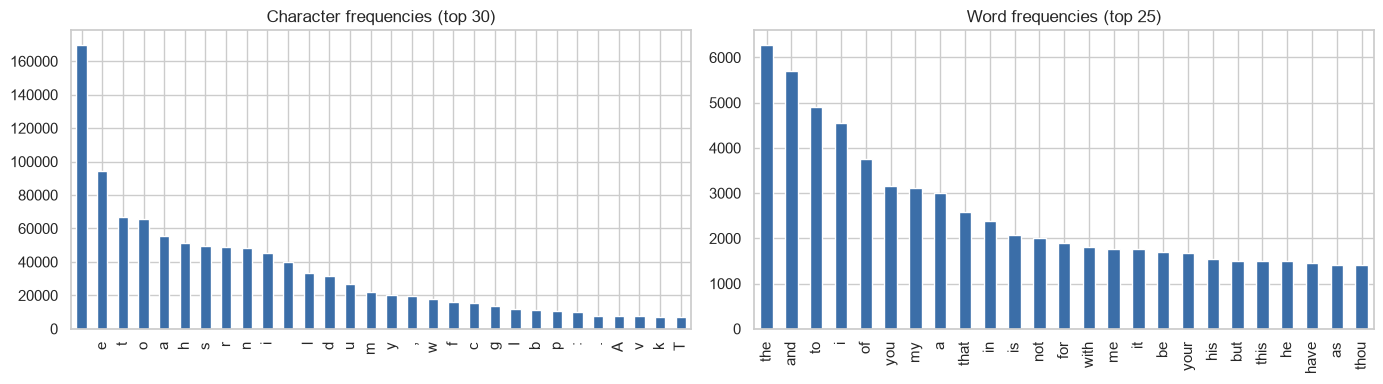

In [2]:
freq = pd.Series(collections.Counter(text)).sort_values(ascending=False); print("most frequent characters:", {repr(k): int(v) for k, v in freq.head(8).items()})
words = re.findall(r"[A-Za-z']+", text.lower()); wc = collections.Counter(words); print("%d words, %d distinct | lines: %d | speakers (lines ending in ':'): %d" % (len(words), len(wc), text.count("\n"), len(re.findall(r"^[A-Z][A-Za-z ]+:$", text, flags=re.M))))
print("entropy of the letter distribution: %.2f bits (uniform over %d symbols would be %.2f)" % (-(freq / freq.sum() * np.log2(freq / freq.sum())).sum(), V, math.log2(V)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); freq.head(30).plot.bar(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Character frequencies (top 30)"); pd.Series(wc).sort_values(ascending=False).head(25).plot.bar(ax=ax[1], color="#3b6ea8"); ax[1].set_title("Word frequencies (top 25)")
plt.tight_layout(); plt.show()

**Reading it.** The text is 1.1 million characters over 65 distinct symbols (letters, punctuation, newline), about 204,000 words of which 12,631 are distinct, and 7,805 speaker lines such as `ROMEO:`. The letter distribution has an entropy of 4.78 bits against 6.02 for a uniform choice among 65 symbols, so even the crudest model (letter frequencies alone) can beat random guessing; the interesting question is how far the context of previous characters takes a model beyond that. The data is a single author's early-modern English with a regular play layout (speaker name, colon, lines), which is easy for a model to imitate and says little about general text.

## 3. Baselines that just count
Cross-entropy on the validation text in **nats per character** (lower = better; a uniform guess over the characters costs ln 65 = 4.17). n-gram models predict a character from the previous 0, 1, 2 or 4 characters with add-k smoothing.

In [3]:
tr_s, va_s = text[:n], text[n:]; base = {"uniform": math.log(V)}
def ngram_loss(order, k=0.05):
    cnt = collections.defaultdict(collections.Counter)
    for i in range(order, len(tr_s)): cnt[tr_s[i - order:i]][tr_s[i]] += 1
    nll, m = 0.0, 0
    for i in range(order, len(va_s)):
        c = cnt.get(va_s[i - order:i]); tot = sum(c.values()) if c else 0; p = ((c[va_s[i]] if c else 0) + k) / (tot + k * V); nll -= math.log(p); m += 1
    return nll / m
for o in (0, 1, 2, 4): base[f"{o}-char context (n-gram)"] = ngram_loss(o)
B = pd.Series(base).rename("val loss (nats/char)"); print(B.round(3).to_string()); print("in bits per character:", (B / math.log(2)).round(2).to_dict())

uniform                    4.174
0-char context (n-gram)    3.347
1-char context (n-gram)    2.485
2-char context (n-gram)    2.050
4-char context (n-gram)    1.757
in bits per character: {'uniform': 6.02, '0-char context (n-gram)': 4.83, '1-char context (n-gram)': 3.58, '2-char context (n-gram)': 2.96, '4-char context (n-gram)': 2.53}


## 4. The transformer, built from its parts
`d_model` 128, 4 heads, 4 layers, context of 128 characters, dropout 0.1, learned position embeddings; each block = layer norm -> masked multi-head self-attention -> residual add; layer norm -> two-layer feed-forward (4x wider) -> residual add. About 0.8 million parameters. The *mask* makes every position see only earlier characters, so the model can be trained to predict the next character everywhere in a window at once.

In [4]:
D, H, L, CTX, DROP = 128, 4, 4, 128, 0.1
class Head(nn.Module):
    def __init__(self, hs): super().__init__(); self.k = nn.Linear(D, hs, bias=False); self.q = nn.Linear(D, hs, bias=False); self.v = nn.Linear(D, hs, bias=False); self.register_buffer("mask", torch.tril(torch.ones(CTX, CTX))); self.drop = nn.Dropout(DROP)
    def forward(self, x):
        B_, T_, _ = x.shape; k, q, v = self.k(x), self.q(x), self.v(x); w = (q @ k.transpose(-2, -1)) * k.shape[-1] ** -0.5; w = w.masked_fill(self.mask[:T_, :T_] == 0, float("-inf")); w = self.drop(F.softmax(w, -1)); self.last = w.detach(); return w @ v
class MHA(nn.Module):
    def __init__(self): super().__init__(); self.heads = nn.ModuleList(Head(D // H) for _ in range(H)); self.proj = nn.Linear(D, D); self.drop = nn.Dropout(DROP)
    def forward(self, x): return self.drop(self.proj(torch.cat([h(x) for h in self.heads], -1)))
class Block(nn.Module):
    def __init__(self): super().__init__(); self.sa = MHA(); self.ff = nn.Sequential(nn.Linear(D, 4 * D), nn.GELU(), nn.Linear(4 * D, D), nn.Dropout(DROP)); self.l1, self.l2 = nn.LayerNorm(D), nn.LayerNorm(D)
    def forward(self, x): x = x + self.sa(self.l1(x)); return x + self.ff(self.l2(x))
class GPT(nn.Module):
    def __init__(self): super().__init__(); self.tok = nn.Embedding(V, D); self.pos = nn.Embedding(CTX, D); self.blocks = nn.Sequential(*[Block() for _ in range(L)]); self.ln = nn.LayerNorm(D); self.out = nn.Linear(D, V)
    def forward(self, idx, targets=None):
        T_ = idx.shape[1]; x = self.tok(idx) + self.pos(torch.arange(T_)); lo = self.out(self.ln(self.blocks(x)))
        return lo, (F.cross_entropy(lo.reshape(-1, V), targets.reshape(-1)) if targets is not None else None)
    @torch.no_grad()
    def generate(self, idx, n_new, temperature=1.0, top_k=None):
        for _ in range(n_new):
            lo, _ = self(idx[:, -CTX:]); lo = lo[:, -1] / max(temperature, 1e-6)
            if top_k: v, _ = torch.topk(lo, top_k); lo[lo < v[:, [-1]]] = float("-inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(lo, -1), 1)], 1)
        return idx
model = GPT(); print("parameters: %.2f M" % (sum(p.numel() for p in model.parameters()) / 1e6))
def batch(split, bs=32):
    d = trn if split == "train" else val; ix = torch.randint(len(d) - CTX - 1, (bs,)); return torch.stack([d[i:i + CTX] for i in ix]), torch.stack([d[i + 1:i + CTX + 1] for i in ix])
@torch.no_grad()
def est(split, k=40): model.eval(); l = np.mean([model(*batch(split))[1].item() for _ in range(k)]); model.train(); return l

parameters: 0.82 M


## 5. Training (3,000 steps of 32 windows of 128 characters; AdamW with cosine learning-rate decay)

In [5]:
STEPS = 3000; opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS, eta_min=3e-4); hist = []; t0 = time.time(); model.train()
for step in range(1, STEPS + 1):
    xb, yb = batch("train"); _, loss = model(xb, yb); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    if step % 250 == 0 or step == 1: hist.append((step, est("train"), est("val"))); print(f"step {step}: train {hist[-1][1]:.3f} | validation {hist[-1][2]:.3f} ({time.time()-t0:.0f}s)")

step 1: train 3.521 | validation 3.535 (9s)


step 250: train 2.020 | validation 2.072 (228s)


step 500: train 1.708 | validation 1.873 (446s)


step 750: train 1.574 | validation 1.754 (706s)


step 1000: train 1.511 | validation 1.703 (1018s)


step 1250: train 1.461 | validation 1.662 (1325s)


... (3 outputs left out)

step 2250: train 1.357 | validation 1.574 (2543s)


step 2500: train 1.339 | validation 1.559 (2849s)


step 2750: train 1.324 | validation 1.551 (3148s)


step 3000: train 1.319 | validation 1.546 (3458s)


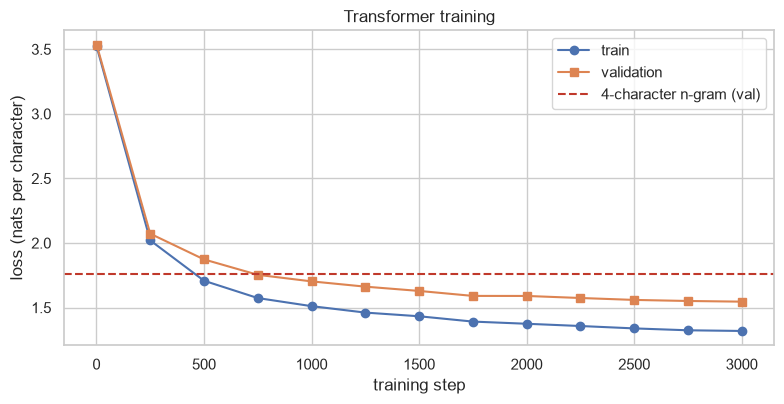

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot([s for s, _, _ in hist], [t for _, t, _ in hist], "o-", label="train"); ax.plot([s for s, _, _ in hist], [v for _, _, v in hist], "s-", label="validation")
ax.axhline(B["4-char context (n-gram)"], color="#c0392b", ls="--", label="4-character n-gram (val)"); ax.set_xlabel("training step"); ax.set_ylabel("loss (nats per character)"); ax.legend(); ax.set_title("Transformer training"); plt.tight_layout(); plt.show()

**Reading it (validation loss in nats per character; lower is better).** The transformer ends at **1.546** on text it never trained on, against **1.757** for the best counting baseline (looks back 4 characters), 2.050 (2 characters), 2.485 (1 character), 3.347 (letter frequencies only) and 4.174 (uniform). In bits per character that is 2.23 for the transformer against 2.53 for the 4-character counter, a reduction of about 12%. Training loss ends at 1.319, so the gap between training and validation is about 0.23 nats and has widened steadily from about 0.01 at the start; the model is starting to fit its training text more closely than new text. Validation loss was still falling slowly at the last evaluation (1.559 -> 1.551 -> 1.546 over the last 500 steps), so a longer run, more dropout or more data could change the result; I did not test this. The model has 0.82 million parameters and took about 58 minutes on a CPU shared with other jobs. With a single training run I cannot say how much of the 0.21-nat advantage over the counter would vary with another random seed.

## 6. How much of the context does the model use?
The trained model is evaluated on validation windows but given only the last *c* characters of context (c = 1, 2, 4, 8, 16, 32, 64, 128): positions with less history than c see all they have.

1      2.518
2      2.112
4      1.699
8      1.577
16     1.553
32     1.536
64     1.534
128    1.523


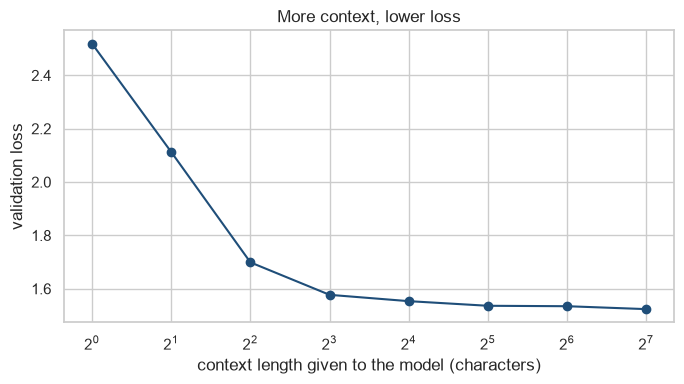

In [7]:
model.eval(); res = {}
with torch.no_grad():
    for c in (1, 2, 4, 8, 16, 32, 64, 128):
        ls = []
        for _ in range(60):
            xb, yb = batch("val", 16); tot = 0.0
            lo = torch.stack([model(xb[:, max(0, t - c + 1):t + 1])[0][:, -1] for t in range(CTX // 2, CTX, 4)], 1)           # predictions at positions 64, 68, ... 124 using only the last c chars
            tg = torch.stack([yb[:, t] for t in range(CTX // 2, CTX, 4)], 1); ls.append(F.cross_entropy(lo.reshape(-1, V), tg.reshape(-1)).item())
        res[c] = np.mean(ls)
CT = pd.Series(res).rename("val loss (nats/char)"); print(CT.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(list(res), list(res.values()), "o-", color="#1f4e79"); ax.set_xscale("log", base=2); ax.set_xlabel("context length given to the model (characters)"); ax.set_ylabel("validation loss"); ax.set_title("More context, lower loss"); plt.tight_layout(); plt.show()

**Reading it (a separate, smaller evaluation: predictions at positions 64 to 124 of validation windows, so the 128-character figure of 1.523 differs slightly from the 1.546 above because of which positions and batches were drawn).** With **1** character of context the loss is 2.518, with 2: 2.112, with 4: 1.699, with 8: 1.577, with 16: 1.553 and then it flattens (1.536 at 32, 1.534 at 64, 1.523 at 128). Almost all of the benefit arrives within the last 8 characters, which is about one word; the part from 8 to 128 characters of context adds only about 0.05 nats. The model is mostly spelling and word shape, and uses the longer range (names of speakers, line structure) only weakly. Note that the 4-character counter at 1.757 is not far above the transformer given 4 characters (1.699), so the transformer's advantage comes both from a better use of the short context and from the longer context.

## 7. Generated text and how to judge it
Samples from the same prompt at four temperatures (low = cautious, high = adventurous), 400 characters each. Then objective measures over 20 samples of 600 characters at each temperature, compared with the real validation text and with a 4-character n-gram generator:
* **valid-word rate:** share of generated words that occur in the training text;
* **repetition:** share of word 3-grams that occur more than once within the sample;
* **distinct-3:** share of distinct character 12-grams (diversity);
* **copying:** share of 40-character strings in the sample that appear *verbatim* in the training text.

In [8]:
prompt = torch.tensor([[stoi[c] for c in "\nROMEO:\n"]]); torch.manual_seed(1)
for temp in (0.5, 0.8, 1.0, 1.3): print(f"--- temperature {temp} ---"); print("".join(itos[i] for i in model.generate(prompt.clone(), 330, temp)[0].tolist()))

--- temperature 0.5 ---



ROMEO:
What shall she but in the state of my son,
That was a consent and more a man poor and gains,
And shall be stooped the sent of the wisery of the death,
Who will be many my brother to the revenge is ready.

CORIOLANUS:
You that we shall have been to say thee that I live,
Shall I have thee in the most of this point to see the sacre
--- temperature 0.8 ---



ROMEO:
Now, you old make our brother prevents thousands
Have the call of a will that one sense
And ay, there is my mother, be younging and show
That thus brother should hath been done:
No, let us, as the soul ease the came of the court?

Clown:
O this princes and loves as a world for no good
stricies, and all the world by honour.'

CLA
--- temperature 1.0 ---



ROMEO:
'Tis deserver Montague's time banish'd,' all a tent
Pardon and bad of the best mescue itself;
I beseech; that we have seed been
I say with Edward's death, speak the woman?

POMPEY:
Satisfy he said, I feed mine of hither as no more;
For dready, get my rodesty truth, as a bown of triumph,
Than might cannot thou lady down in his wa
--- temperature 1.3 ---



ROMEO:
You sceivetething in all is standance.

POMPEY:
Old I that lord, and cludafidius fand
Who should I come as the smile to ta cane. You, there, sit you
be one invionmise
OXFOTAR Flivort? Ha!
Mock thoo Plew of Romeo.
What hoopeabers ere his rippared!
Go give their Mercy cannot kiss'd an of;
Nor yetter laids, Camillars, my kindure to


In [9]:
vocab_words = set(words); train_text = tr_s
def n4_generate(n_chars, temp=1.0, seed=0):
    cnt = collections.defaultdict(collections.Counter)
    for i in range(4, len(tr_s)): cnt[tr_s[i - 4:i]][tr_s[i]] += 1
    r = np.random.RandomState(seed); out = list("\nROMEO:\n")
    while len(out) < n_chars:
        c = cnt.get("".join(out[-4:]))
        if not c: out.append(r.choice(chars)); continue
        k, v = zip(*c.items()); p = np.array(v, float) ** (1 / temp); out.append(r.choice(k, p=p / p.sum()))
    return "".join(out)
def measure(s):
    w = re.findall(r"[A-Za-z']+", s.lower()); valid = np.mean([x in vocab_words for x in w]) if w else 0; tri = list(zip(w, w[1:], w[2:])); rep = 1 - len(set(tri)) / max(1, len(tri))
    g12 = [s[i:i + 12] for i in range(len(s) - 12)]; div = len(set(g12)) / max(1, len(g12)); g40 = [s[i:i + 40] for i in range(0, len(s) - 40, 10)]; cp = np.mean([g in train_text for g in g40]) if g40 else 0
    return valid * 100, rep * 100, div * 100, cp * 100
rows = {}
for temp in (0.5, 0.8, 1.0, 1.3):
    ms = []
    torch.manual_seed(100 + int(temp * 10)); gen = model.generate(prompt.repeat(20, 1), 592, temp)          # 20 independent samples generated as one batch
    for row in gen: ms.append(measure("".join(itos[i] for i in row.tolist())))
    rows[f"transformer, T={temp}"] = np.mean(ms, 0)
rows["4-char n-gram, T=1.0"] = np.mean([measure(n4_generate(600, 1.0, sd)) for sd in range(10)], 0)
vs = [text[n + i:n + i + 600] for i in range(0, 20 * 600, 600)]; rows["real validation text"] = np.mean([measure(s) for s in vs], 0)
GM = pd.DataFrame(rows, index=["valid words %", "repeated word 3-grams %", "distinct 12-grams %", "40-char strings copied from training %"]).T; print(GM.round(1).to_string())

                      valid words %  repeated word 3-grams %  distinct 12-grams %  40-char strings copied from training %
transformer, T=0.5             97.9                      0.7                 99.2                                     0.0
transformer, T=0.8             92.6                      0.0                100.0                                     0.0
transformer, T=1.0             89.2                      0.0                 99.9                                     0.0
transformer, T=1.3             76.7                      0.0                100.0                                     0.0
4-char n-gram, T=1.0           89.4                      0.0                 99.9                                     0.0
real validation text           99.0                      0.7                 98.3                                     0.0


**Reading the samples.** At temperature 0.5 the text looks like Shakespeare in rhythm and layout (speaker names, short lines) but is not meaningful: "What shall she but in the state of my son, / That was a consent and more a man poor and gains" is grammatical-looking nonsense. At 1.0 invented words appear ("dready", "rodesty", "bown"), and at 1.3 most lines are broken ("OXFOTAR Flivort?").

**Reading the measures (20 samples of 600 characters per temperature; no confidence intervals, so differences of a point or two should not be interpreted).**
* **Valid words** falls steadily with temperature: 97.9% (T=0.5), 92.6%, 89.2%, 76.7% (T=1.3), against 99.0% for real validation text (not 100% because some real words never occur in the training text). The measure only checks that a word occurs in the training text, not that it is used correctly.
* **The transformer is not ahead of the counting model on this measure at the same temperature:** at T=1.0 the transformer has 89.2% valid words and the 4-character generator 89.4%. The lower loss (1.546 against 1.757) is real, but it does not show up here at T=1.0; whether the transformer is better at lower temperatures than the counter was not tested (the counter was only generated at T=1.0).
* **Repetition** (repeated word 3-grams) is 0.0-0.7% everywhere, equal to real text, and **distinct 12-grams** is 98-100% everywhere, so these two measures cannot tell the settings apart at this sample length; they are mostly useful to detect a model that has collapsed into loops, which this one has not.
* **Copying:** none of the 40-character windows are found verbatim in the training text (0.0% at every temperature), including at T=0.5. Real validation text also scores 0.0%, which is expected because the validation text is held out. Within this test the model does not copy long stretches. It does not rule out copying of shorter pieces, which with a 128-character context and a 1-million-character training text would be expected to occur for common phrases.

## 8. A look inside: where does one attention head look?

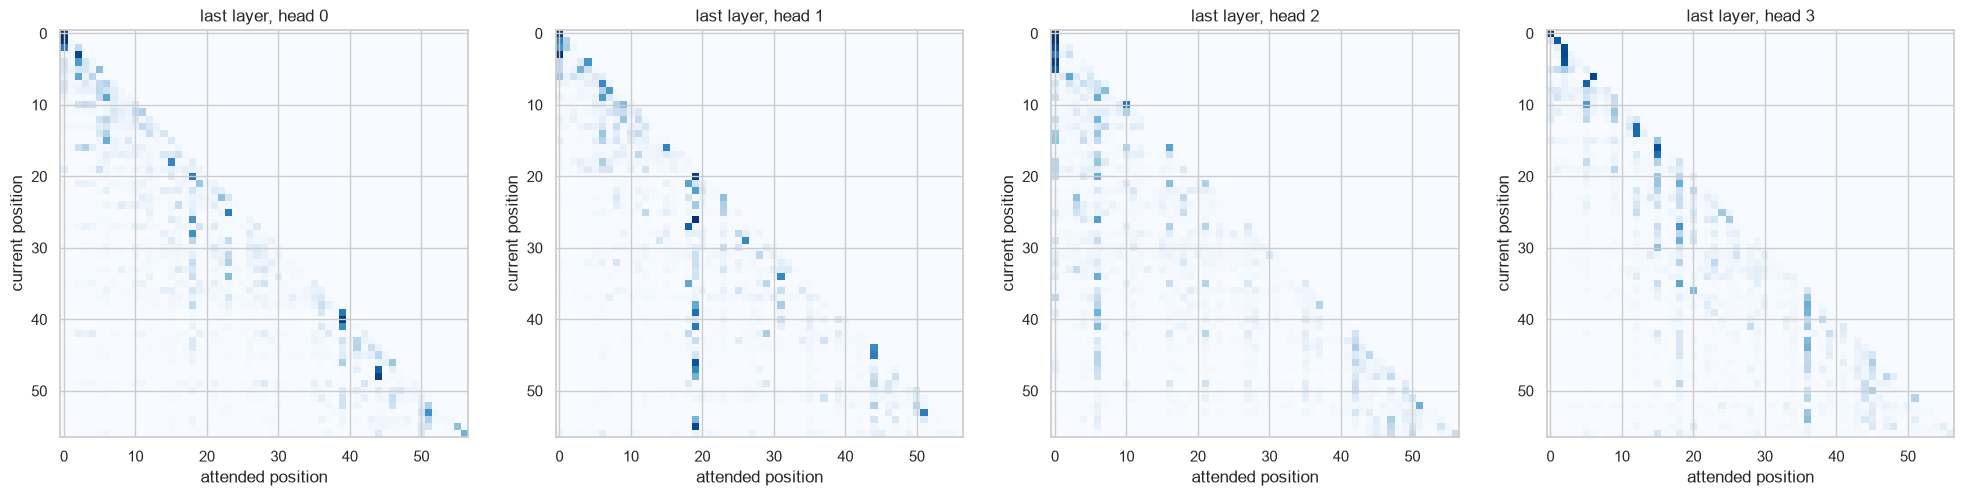

average distance (characters back) attended to, by head, per layer: {'layer 0': [1.6, 3.3, 2.6, 1.7], 'layer 1': [4.1, 6.1, 2.7, 3.4], 'layer 2': [4.4, 12.1, 6.6, 4.6], 'layer 3': [7.3, 9.3, 12.3, 8.2]}


In [10]:
sample = "ROMEO:\nBut soft, what light through yonder window breaks?"; x = torch.tensor([[stoi[c] for c in sample]])
with torch.no_grad(): model(x)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for h_, a_ in enumerate(ax): w = model.blocks[-1].sa.heads[h_].last[0].numpy(); a_.imshow(w, cmap="Blues"); a_.set_title(f"last layer, head {h_}"); a_.set_xlabel("attended position"); a_.set_ylabel("current position")
plt.tight_layout(); plt.show()
dist = lambda w: float(np.mean([(w[t, :t + 1] * (t - np.arange(t + 1))).sum() for t in range(1, w.shape[0])]))
print("average distance (characters back) attended to, by head, per layer:", {f"layer {l_}": [round(dist(model.blocks[l_].sa.heads[h_].last[0].numpy()), 1) for h_ in range(H)] for l_ in range(L)})

**Reading it (one 57-character sentence, so only an illustration).** The average distance attended back, by layer, is **1.6-3.3 characters in layer 0, 2.7-6.1 in layer 1, 4.4-12.1 in layer 2 and 7.3-12.3 in layer 3**: early layers look at the immediate neighbours (the diagonal stripe in the heatmaps), later layers reach farther, and some heads in the last layer keep returning to a few specific earlier positions (the vertical stripes in heads 1 to 3). That fits the context test above (the neighbouring few characters matter most). Heatmaps show where a head puts its weight, not why; it is a fact about this one model and sentence and should not be read as "this head does X" without further tests.

## 9. Save

In [11]:
torch.save(model.state_dict(), "model/mini_gpt.pt"); json.dump({"chars": chars, "D": D, "H": H, "L": L, "CTX": CTX}, open("model/config.json", "w"))
json.dump({"baselines": B.round(4).to_dict(), "val_loss": float(hist[-1][2]), "context": CT.round(4).to_dict(), "generation": GM.round(2).to_dict("index"), "history": hist}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['config.json', 'meta.json', 'mini_gpt.pt']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Model | a small generative model built and run | a decoder-only transformer written from its parts (0.82 M parameters, 4 layers, 4 heads, context 128) |
| Evaluation | a text sample shown | validation loss against counting baselines: **1.546** vs 1.757 (4-character n-gram), 4.174 (uniform) |
| Context | not examined | loss flattens after about 8 characters of context (1.577 at 8, 1.523 at 128) |
| Generated text | one sample | four temperatures, objective measures: valid words 97.9% (T=0.5) to 76.7% (T=1.3), no verbatim 40-character copying |
| Inside the model | not shown | attention distance grows with depth (about 2 characters in layer 0, up to about 12 in layer 3) |

**What I learned.** (1) A language model should be judged first by held-out loss against simple baselines; here the transformer's gain over a 4-character counter is real but moderate (about 12%). (2) Most of the useful context is the last few characters; a longer window helped little for a model this small. (3) Sample quality measures at this scale (valid words, repetition, copying) are blunt: several did not separate the settings, and at T=1.0 the counting model matched the transformer on valid words. (4) Temperature is a trade between fluency and variety, not a quality knob. (5) Reading generated text by eye is easy to over-trust: it *sounds* like Shakespeare while meaning almost nothing.

**Limits.** Characters, not words (so the vocabulary is tiny and spelling is part of the task); one training run, one seed, no tuning of size or learning rate; the validation set is the last 10% of one play collection, so style is not independent of the training part; the measures use 20 samples per setting with no intervals; the model is far too small to say anything about large models. **Next step:** repeat with several seeds, add dropout or early stopping (the train-validation gap is growing), and compare a word-piece vocabulary.